# Solving the Traveling Salesman Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$.

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  >
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)

In [2]:
def random_tour(n):
    """Create a random tour"""

    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[1, 2, 8, 6, 4, 7, 9, 5, 0, 3]

In [3]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a
    pairwise Euclidean distance matrix.
    """

    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })

    dist = squareform(pdist(pos))

    return({"pos": pos, "dist": dist})

tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [4]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""

    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()

    tl = 0
    dist = tsp["dist"]

    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]

    tl += dist[tour[-1], tour[0]]

    return(tl)

tour = random_tour(10)
tour_length(tsp, tour)

np.float64(4.4721151033843585)

Tour length: 4.47


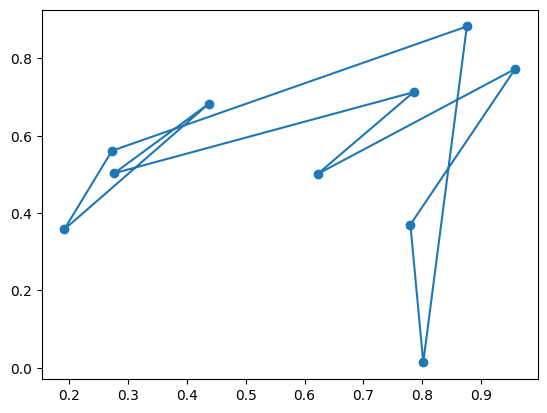

In [5]:
def show_tsp(tsp, tour = None):
    """display the traveling salesman problem and a tour."""

    pos = tsp["pos"]

    plt.scatter(pos["x"], pos["y"])

    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()

        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")

        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])

    plt.show()

show_tsp(tsp, tour)

## Bài 7 - Mô hình hoá và toán tử lân cận

* **Trạng thái:** hoán vị `tour` của `n` thành phố. **Hàm mục tiêu:** `tour_length(tsp, tour)` = tổng độ dài chu trình khép kín (có cả cạnh từ thành phố cuối về thành phố đầu). Cần **minimize**.
* **Toán tử lân cận (dùng thống nhất khi so sánh thuật toán):** *swap* - hoán đổi vị trí của 2 thành phố `i < j` trong tour. Số láng giềng là $\binom{n}{2} = n(n-1)/2$ (n=10: 45, n=50: 1225). Mọi kết quả hoán vị đều hợp lệ nên ràng buộc "là hoán vị" luôn thoả.
* **Toán tử thay thế (để trả lời câu hỏi 10):** *2-opt* - đảo ngược đoạn `tour[i..j]`. Cũng có $\binom{n}{2}$ láng giềng nhưng mỗi láng giềng chỉ đổi 2 cạnh của tour (swap đổi tới 4 cạnh), nên thay đổi "mượt" hơn và hay cải thiện tour hơn.

In [6]:
import time, itertools

def seed_all(s):
    """Đặt seed cho random (random_tour dùng) và numpy (random_tsp dùng)."""
    random.seed(s); np.random.seed(s)

# ---- toán tử lân cận: nhận (tour, i, j) trả về tour mới ----
def apply_swap(tour, i, j):
    t = list(tour); t[i], t[j] = t[j], t[i]; return t

def apply_2opt(tour, i, j):
    return list(tour[:i]) + list(tour[i:j + 1][::-1]) + list(tour[j + 1:])

OPS = {"swap": apply_swap, "2opt": apply_2opt}

def all_pairs(n): return [(i, j) for i in range(n - 1) for j in range(i + 1, n)]

seed_all(1)
tsp = random_tsp(8)
tour = random_tour(8)
print("Số láng giềng của n=8:", len(all_pairs(8)))
print("Tour:", tour, "| độ dài:", round(tour_length(tsp, tour), 3))
print("Sau swap(0,3):", apply_swap(tour, 0, 3), "| sau 2opt(1,4):", apply_2opt(tour, 1, 4))

Số láng giềng của n=8: 28
Tour: [3, 6, 1, 5, 7, 0, 4, 2] | độ dài: 3.726
Sau swap(0,3): [5, 6, 1, 3, 7, 0, 4, 2] | sau 2opt(1,4): [3, 7, 5, 1, 6, 0, 4, 2]


## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (move each queen within its column) and always choose the best among all local moves.

In [7]:
# ---------- Steepest-ascent Hill Climbing (minimize tour_length) ----------
# Mỗi thuật toán trả về dict: tour cuối, length cuối, iters, evals (số lần gọi tour_length), hist (độ dài theo vòng lặp)

def steepest_hc(tsp, tour, op="swap", max_iter=100000):
    apply = OPS[op]; n = len(tour); tour = list(tour)
    cur = tour_length(tsp, tour); evals = 1; hist = [cur]; it = 0
    pairs = all_pairs(n)
    while it < max_iter:
        best_len, best_tour = cur, None
        for i, j in pairs:                    # xét TOÀN BỘ láng giềng, chọn cái ngắn nhất
            nt = apply(tour, i, j); L = tour_length(tsp, nt); evals += 1
            if L < best_len - 1e-12: best_len, best_tour = L, nt
        if best_tour is None: break           # không còn cải thiện -> local optimum
        tour, cur = best_tour, best_len; it += 1; hist.append(cur)
    return dict(tour=tour, length=cur, iters=it, evals=evals, hist=hist)

seed_all(42)
tsp = random_tsp(15)
t0_tour = random_tour(15)
r = steepest_hc(tsp, t0_tour)
print(f"n=15: độ dài đầu = {tour_length(tsp, t0_tour):.3f} -> sau steepest (swap) = {r['length']:.3f}, {r['iters']} bước, {r['evals']} lần đánh giá")

n=15: độ dài đầu = 8.629 -> sau steepest (swap) = 3.175, 12 bước, 1366 lần đánh giá


## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

In [8]:
# ---------- Steepest-ascent với Random Restart ----------
def random_restart(tsp, n, algo=steepest_hc, restarts=10, **kw):
    """Chạy `algo` từ `restarts` tour ngẫu nhiên khác nhau và giữ kết quả tốt nhất."""
    best = None; evals = iters = 0
    for _ in range(restarts):
        r = algo(tsp, random_tour(n), **kw); evals += r["evals"]; iters += r["iters"]
        if best is None or r["length"] < best["length"]: best = r
    return dict(tour=best["tour"], length=best["length"], iters=iters, evals=evals, hist=best["hist"])

seed_all(42)
r = random_restart(tsp, 15, restarts=10)
print(f"n=15, 10 restart: độ dài tốt nhất = {r['length']:.3f}, tổng số lần đánh giá = {r['evals']}")

n=15, 10 restart: độ dài tốt nhất = 3.175, tổng số lần đánh giá = 10510


## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

In [9]:
# ---------- Stochastic Hill Climbing: chọn ngẫu nhiên trong TẤT CẢ nước đi cải thiện ----------
def stochastic_hc(tsp, tour, op="swap", max_iter=100000):
    apply = OPS[op]; n = len(tour); tour = list(tour)
    cur = tour_length(tsp, tour); evals = 1; hist = [cur]; it = 0
    pairs = all_pairs(n)
    while it < max_iter:
        improving = []
        for i, j in pairs:
            nt = apply(tour, i, j); L = tour_length(tsp, nt); evals += 1
            if L < cur - 1e-12: improving.append((nt, L))
        if not improving: break
        tour, cur = random.choice(improving); it += 1; hist.append(cur)
    return dict(tour=tour, length=cur, iters=it, evals=evals, hist=hist)

seed_all(42)
r = stochastic_hc(tsp, t0_tour)
print(f"n=15: stochastic HC -> {r['length']:.3f}, {r['iters']} bước, {r['evals']} lần đánh giá")

n=15: stochastic HC -> 3.120, 21 bước, 2311 lần đánh giá


## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

In [10]:
# ---------- First-choice Hill Climbing ----------
def first_choice_hc(tsp, tour, op="swap", max_fail=None, max_iter=10**6):
    """Sinh 1 láng giềng ngẫu nhiên mỗi lần, nhận nếu ngắn hơn. Dừng sau max_fail lần thất bại liên tiếp,
    mặc định x = N*(ln N + 2) với N = n(n-1)/2 (coupon collector: gần như đã thử hết mọi láng giềng)."""
    apply = OPS[op]; n = len(tour); tour = list(tour)
    N = n * (n - 1) // 2
    if max_fail is None: max_fail = math.ceil(N * (math.log(N) + 2))
    cur = tour_length(tsp, tour); evals = 1; hist = [cur]; it = fails = 0
    while fails < max_fail and it < max_iter:
        i, j = sorted(random.sample(range(n), 2))
        nt = apply(tour, i, j); L = tour_length(tsp, nt); evals += 1; it += 1
        if L < cur - 1e-12: tour, cur, fails = nt, L, 0
        else: fails += 1
        hist.append(cur)
    return dict(tour=tour, length=cur, iters=it, evals=evals, hist=hist)

seed_all(42)
r = first_choice_hc(tsp, t0_tour)
print(f"n=15: first-choice -> {r['length']:.3f}, {r['iters']} lần thử, {r['evals']} lần đánh giá")

n=15: first-choice -> 3.858, 1222 lần thử, 1223 lần đánh giá


## Simulated Annealing [2 Points]

In [11]:
# ---------- Simulated Annealing ----------
def simulated_annealing(tsp, tour, op="swap", max_iter=None, T0=None, T_end=1e-3):
    """Lịch nhiệt mũ T(t) = T0 * alpha^t, alpha chọn sao cho T giảm từ T0 xuống T_end đúng sau max_iter vòng.
    T0 mặc định = độ dài trung bình 1 cạnh của tour đầu (cùng cỡ với delta của 1 nước đi).
    Nhận nước xấu hơn với xác suất exp(-delta/T). Trả về tour TỐT NHẤT từng gặp."""
    apply = OPS[op]; n = len(tour); tour = list(tour)
    cur = tour_length(tsp, tour); evals = 1
    if max_iter is None: max_iter = 500 * n
    if T0 is None: T0 = cur / n
    alpha = (T_end / T0) ** (1 / max_iter)
    best, best_len = list(tour), cur; hist = [cur]; T = T0
    for it in range(1, max_iter + 1):
        T *= alpha
        i, j = sorted(random.sample(range(n), 2))
        nt = apply(tour, i, j); L = tour_length(tsp, nt); evals += 1
        d = L - cur
        if d < 0 or random.random() < math.exp(-d / T):
            tour, cur = nt, L
            if cur < best_len: best, best_len = list(tour), cur
        hist.append(best_len)
    return dict(tour=best, length=best_len, iters=max_iter, evals=evals, hist=hist)

seed_all(42)
r = simulated_annealing(tsp, t0_tour)
print(f"n=15: SA -> {r['length']:.3f}, {r['iters']} vòng, {r['evals']} lần đánh giá")

n=15: SA -> 3.172, 7500 vòng, 7501 lần đánh giá


**Mô tả các thuật toán và lựa chọn thiết kế:**

* Tất cả dùng chung toán tử **swap** (hoán đổi 2 thành phố) và hàm mục tiêu `tour_length()`; mỗi thuật toán trả về tour, độ dài, số bước, số lần gọi `tour_length` (evals).
* **Steepest**: xét toàn bộ n(n-1)/2 cặp, chọn tour ngắn nhất, dừng khi không còn tour nào ngắn hơn. **Random Restart**: chạy steepest từ 10 tour ngẫu nhiên, giữ tour tốt nhất. **Stochastic**: liệt kê mọi nước làm ngắn tour rồi chọn ngẫu nhiên. **First-choice**: bốc 1 cặp ngẫu nhiên, nhận nếu ngắn hơn, dừng sau x = N(ln N + 2) lần thất bại liên tiếp (N = n(n-1)/2, cùng lý do như n-Queens). **SA**: lịch mũ có alpha chọn sao cho T giảm từ T0 (= độ dài trung bình 1 cạnh của tour đầu) xuống 0,001 đúng sau 500n vòng, nhận nước xấu hơn với xác suất exp(-delta/T).
* Ví dụ n=15 ở trên: tour đầu dài 8,63, steepest xuống 3,18 sau 12 bước; first-choice dừng ở 3,86 (kẹt local optimum), SA 3,17. Một lần chạy thì nhiễu, nên phần dưới chạy nhiều lần.

## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [12]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.17571449279785156 milliseconds


In [13]:
# ---------- Thí nghiệm so sánh ----------
# Cùng một instance TSP và cùng các tour khởi đầu cho mọi thuật toán; mỗi cấu hình chạy RUNS lần (tour đầu khác nhau).
# Toán tử lân cận: swap cho tất cả thuật toán.
RUNS, RESTARTS = 5, 10
ALGOS = {
    "Steepest-ascent":        lambda ts, t0, n: steepest_hc(ts, t0),
    "Stochastic (all moves)": lambda ts, t0, n: stochastic_hc(ts, t0),
    "First-choice":           lambda ts, t0, n: first_choice_hc(ts, t0),
    "Steepest + Random Restart": lambda ts, t0, n: random_restart(ts, n, restarts=RESTARTS),
    "Simulated Annealing":    lambda ts, t0, n: simulated_annealing(ts, t0),
}
SIZES = [10, 20, 30, 50]
rows = []
for n in SIZES:
    seed_all(1000 + n)
    tsp_n = random_tsp(n)
    starts = [random_tour(n) for _ in range(RUNS)]
    init_len = np.mean([tour_length(tsp_n, s) for s in starts])
    for name, fn in ALGOS.items():
        seed_all(2000 + n)
        lens, ms, evs, iters = [], [], [], []
        for s in starts:
            t0 = time.perf_counter()
            r = fn(tsp_n, s, n)
            ms.append((time.perf_counter() - t0) * 1e3)

            lens.append(r["length"])
            evs.append(r["evals"])
            iters.append(r["iters"])
        rows.append({
            "n": n,
            "algorithm": name,
            "best length": min(lens),
            "mean length": np.mean(lens),
            "improvement vs initial (%)":
                (1 - np.mean(lens) / init_len) * 100,
            "iterations": np.mean(iters),
            "time (ms)": np.mean(ms),
            "evals": np.mean(evs)
        })
res_tsp = pd.DataFrame(rows)
res_tsp.round(3).to_csv("results_tsp.csv", index=False)
res_tsp.round(3)

,n,algorithm,best length,mean length,improvement vs initial (%),iterations,time (ms),evals
0,10,Steepest-ascent,2.33,2.44,38.51,5.0,0.81,271.0
1,10,Stochastic (all moves),2.33,2.44,38.39,9.4,1.45,469.0
2,10,First-choice,2.33,2.33,41.19,405.4,2.52,406.4
3,10,Steepest + Random Restart,2.33,2.33,41.19,52.2,8.54,2809.0
4,10,Simulated Annealing,2.33,2.33,41.19,5000.0,30.87,5001.0
5,20,Steepest-ascent,4.75,4.94,52.15,14.2,15.65,2889.0
6,20,Stochastic (all moves),4.56,5.11,50.53,30.0,33.91,5891.0
7,20,First-choice,4.85,5.17,49.97,2215.4,17.29,2216.4
8,20,Steepest + Random Restart,4.62,4.70,54.46,129.6,142.44,26534.0
9,20,Simulated Annealing,4.59,4.69,54.64,10000.0,83.53,10001.0


**Nhận xét**:
- Với (n=10), cả năm thuật toán đều tìm được tour có độ dài tốt nhất là 2,33. Khi số thành phố tăng, độ dài tour tốt nhất nhìn chung cũng tăng.
- Tại (n=50), Random Restart cho kết quả tốt nhất với độ dài tour 6,78, tiếp theo là Simulated Annealing với 7,12 và First-choice với 7,61.
- Về thời gian chạy trung bình, First-choice nhanh nhất với 0,211 giây, tiếp theo là Simulated Annealing với 0,243 giây, trong khi Random Restart mất nhiều thời gian nhất với 4,779 giây.
- Nhìn chung, Random Restart tìm được tour ngắn nhất tại (n=50), còn First-choice có ưu điểm về tốc độ. Simulated Annealing cũng cho kết quả khá tốt với thời gian chạy thấp. Tuy nhiên, các kết quả này chỉ dựa trên 5 lần chạy cho mỗi cấu hình nên vẫn có thể chịu ảnh hưởng của tính ngẫu nhiên.


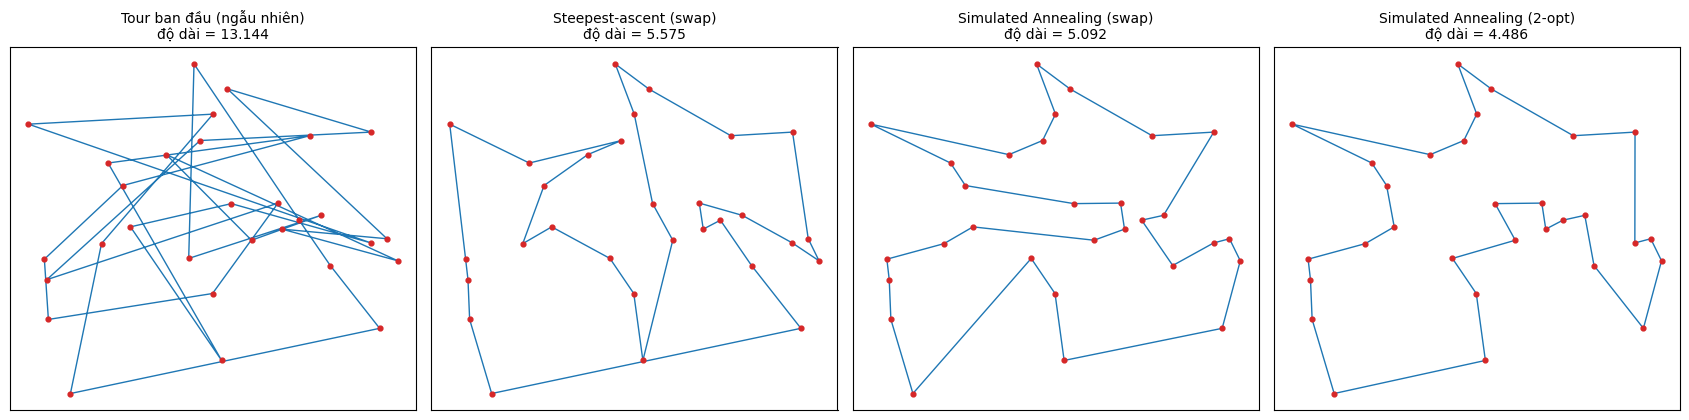

In [14]:
# Tour trước / sau tối ưu (n=30, cùng tour đầu)
def plot_tour(ax, tsp, tour, title):
    pos = tsp["pos"].reindex(list(tour)); pos = pd.concat([pos, pos.head(1)])
    ax.plot(pos["x"], pos["y"], "-", lw=1); ax.scatter(tsp["pos"]["x"], tsp["pos"]["y"], s=12, c="C3", zorder=3)
    ax.set_title(f"{title}\nđộ dài = {tour_length(tsp, tour):.3f}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])

seed_all(7); tsp30 = random_tsp(30); start30 = random_tour(30)
seed_all(8); r_st = steepest_hc(tsp30, start30)
seed_all(8); r_sa = simulated_annealing(tsp30, start30)
seed_all(8); r_sa2 = simulated_annealing(tsp30, start30, op="2opt")
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
plot_tour(axes[0], tsp30, start30, "Tour ban đầu (ngẫu nhiên)")
plot_tour(axes[1], tsp30, r_st["tour"], "Steepest-ascent (swap)")
plot_tour(axes[2], tsp30, r_sa["tour"], "Simulated Annealing (swap)")
plot_tour(axes[3], tsp30, r_sa2["tour"], "Simulated Annealing (2-opt)")
plt.tight_layout(); plt.show()

## Bonus: Genetic Algorithm [+1 Point]

GA (n=30): 4.748 sau 795 ms | SA(swap): 5.092 | SA(2opt): 4.486 | steepest: 5.575


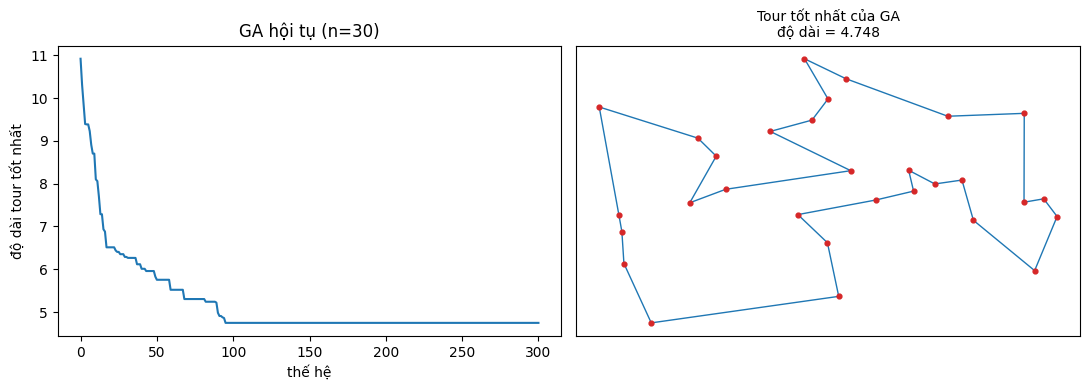

In [15]:
# ---------- Bonus: Genetic Algorithm ----------
def order_crossover(p1, p2):
    """OX: giữ nguyên 1 đoạn của p1, phần còn lại điền theo thứ tự xuất hiện trong p2 (luôn ra hoán vị hợp lệ)."""
    n = len(p1); a, b = sorted(random.sample(range(n), 2))
    child = [None] * n; child[a:b + 1] = p1[a:b + 1]
    rest = [c for c in p2 if c not in child[a:b + 1]]
    k = 0
    for i in range(n):
        if child[i] is None: child[i] = rest[k]; k += 1
    return child

def genetic_algorithm(tsp, n, pop_size=100, generations=300, p_mut=0.2, elite=2, tournament=3):
    pop = [random_tour(n) for _ in range(pop_size)]
    fit = [tour_length(tsp, t) for t in pop]; hist = [min(fit)]
    pick = lambda: min(random.sample(range(pop_size), tournament), key=lambda k: fit[k])   # chọn lọc tournament
    for g in range(generations):
        order = np.argsort(fit); new = [pop[k] for k in order[:elite]]                      # giữ lại elite
        while len(new) < pop_size:
            child = order_crossover(pop[pick()], pop[pick()])
            if random.random() < p_mut:                                                      # đột biến: đảo 1 đoạn
                i, j = sorted(random.sample(range(n), 2)); child = apply_2opt(child, i, j)
            new.append(child)
        pop = new; fit = [tour_length(tsp, t) for t in pop]; hist.append(min(fit))
    k = int(np.argmin(fit))
    return dict(tour=pop[k], length=fit[k], hist=hist, evals=pop_size * (generations + 1))

seed_all(8)
t0 = time.perf_counter(); r_ga = genetic_algorithm(tsp30, 30); dt = (time.perf_counter() - t0) * 1e3
print(f"GA (n=30): {r_ga['length']:.3f} sau {dt:.0f} ms | SA(swap): {r_sa['length']:.3f} | SA(2opt): {r_sa2['length']:.3f} | steepest: {r_st['length']:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(r_ga["hist"]); axes[0].set_xlabel("thế hệ"); axes[0].set_ylabel("độ dài tour tốt nhất"); axes[0].set_title("GA hội tụ (n=30)")
plot_tour(axes[1], tsp30, r_ga["tour"], "Tour tốt nhất của GA")
plt.tight_layout(); plt.show()